# PageRank with Structured Parallelism

A walkthrough of the project: the algorithm, the two parallel patterns, and the benchmark results.
The implementation lives in the [`pagerank`](../pagerank) package; this notebook imports it.

**Run this notebook in a fresh kernel.** The first cell pins NumPy's BLAS library to one thread, which only works before NumPy is imported.

In [1]:
import os
for var in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "OMP_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(var, "1")

import sys, json, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import networkx as nx
from IPython.display import Image, display

from pagerank import (ECOMMERCE_SITE, build_transition_matrix, pagerank_naive,
                      pagerank_sequential, pagerank_data_parallel, synthetic_web_matrix)
from pagerank.tasks import run_tasks_sequential, run_tasks_parallel

## 1. PageRank in one formula

$$PR(p) = \frac{1-d}{N} + d \sum_{q \to p} \frac{PR(q)}{\text{outlinks}(q)}$$

A page is important if important pages link to it. With damping factor $d = 0.85$, a random surfer follows a link 85% of the time and jumps to a random page 15% of the time. The scores are computed by **power iteration**: start with equal ranks and apply the formula until the ranks stop changing.

## 2. The test graph: a 15-page online shop

15 pages, 39 links


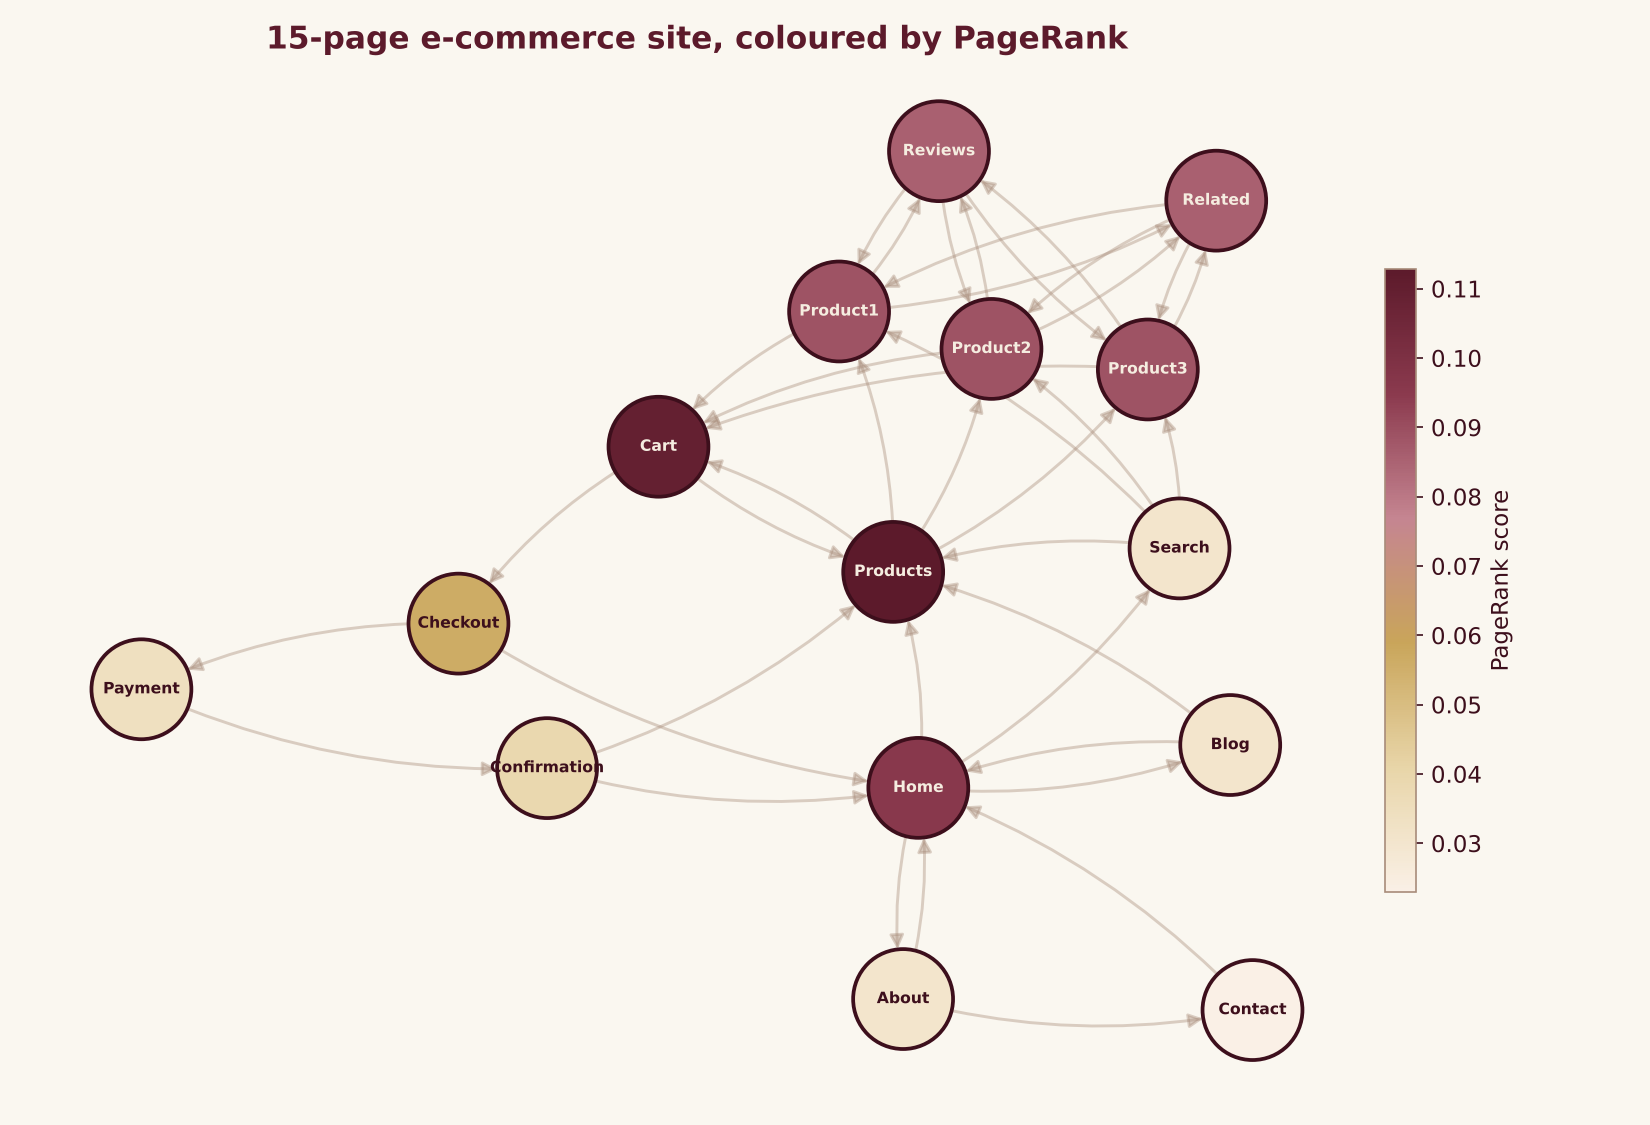

In [2]:
M, nodes = build_transition_matrix(ECOMMERCE_SITE)
print(f"{len(nodes)} pages, {int((M > 0).sum())} links")
display(Image("../images/web_graph.png", width=750))

## 3. Sequential PageRank, checked against NetworkX

In [3]:
ranks, iterations = pagerank_sequential(M)
reference = nx.pagerank(nx.DiGraph(ECOMMERCE_SITE), alpha=0.85, tol=1e-12)

print(f"Converged in {iterations} iterations")
print("Matches networkx.pagerank:", np.allclose(ranks, [reference[n] for n in nodes]))
print("\nTop 5 pages:")
for i in np.argsort(ranks)[::-1][:5]:
    print(f"  {nodes[i]:<10} {ranks[i]:.4f}")

Converged in 42 iterations
Matches networkx.pagerank: True

Top 5 pages:
  Products   0.1129
  Cart       0.1096
  Home       0.0959
  Product3   0.0889
  Product1   0.0889


## 4. Method 1: data parallelism

Every PageRank iteration applies the same update to every row of the matrix. So the rows are split into contiguous blocks and each thread updates its own block (**same operation, different data**). All threads must finish before the next iteration starts, which acts as a barrier.

Threads can run truly in parallel here because NumPy **releases the GIL** during the matrix-vector product.

In [4]:
big = synthetic_web_matrix(2000)
seq, _ = pagerank_sequential(big)
for w in (1, 2, 4, 8):
    par, _ = pagerank_data_parallel(big, n_workers=w)
    print(f"{w} workers: identical to sequential = {np.allclose(par, seq)}")

1 workers: identical to sequential = True
2 workers: identical to sequential = True
4 workers: identical to sequential = True
8 workers: identical to sequential = True


## 5. Method 2: task parallelism

Three **different, independent** analyses of the same graph run at the same time: PageRank scores, HITS hub/authority scores, and structural statistics.

In [5]:
t_seq, results = run_tasks_sequential(big)
t_par, _ = run_tasks_parallel(big)
print(f"Sequential: {t_seq:.3f}s   Parallel: {t_par:.3f}s   (this machine)")
print("Graph statistics:", {k: round(v, 3) if isinstance(v, float) else v for k, v in results[2].items()})

Sequential: 0.158s   Parallel: 0.105s   (this machine)
Graph statistics: {'pages': 2000, 'links': 18650, 'avg_out_degree': 9.325, 'max_in_degree': 1052, 'density': 0.005, 'reciprocity': 0.005, 'dangling_pages': 97}


## 6. Benchmark results

Measured with `python benchmarks/run_benchmarks.py` on a 4-CPU Intel MacBook Air. Each run does 50 iterations, and each time is the median of 7 runs.

Vectorisation alone (n=1000): 5.0x faster than a Python loop

 pages | 1 workers | 2 workers | 4 workers | 8 workers
  1000 |     0.59x |     0.60x |     0.42x |     0.24x
  2000 |     0.84x |     1.09x |     1.11x |     0.98x
  4000 |     0.96x |     1.41x |     1.43x |     1.32x

15-page site: 4 workers are 80x SLOWER than sequential
Task parallelism (n=4000): 1.51x


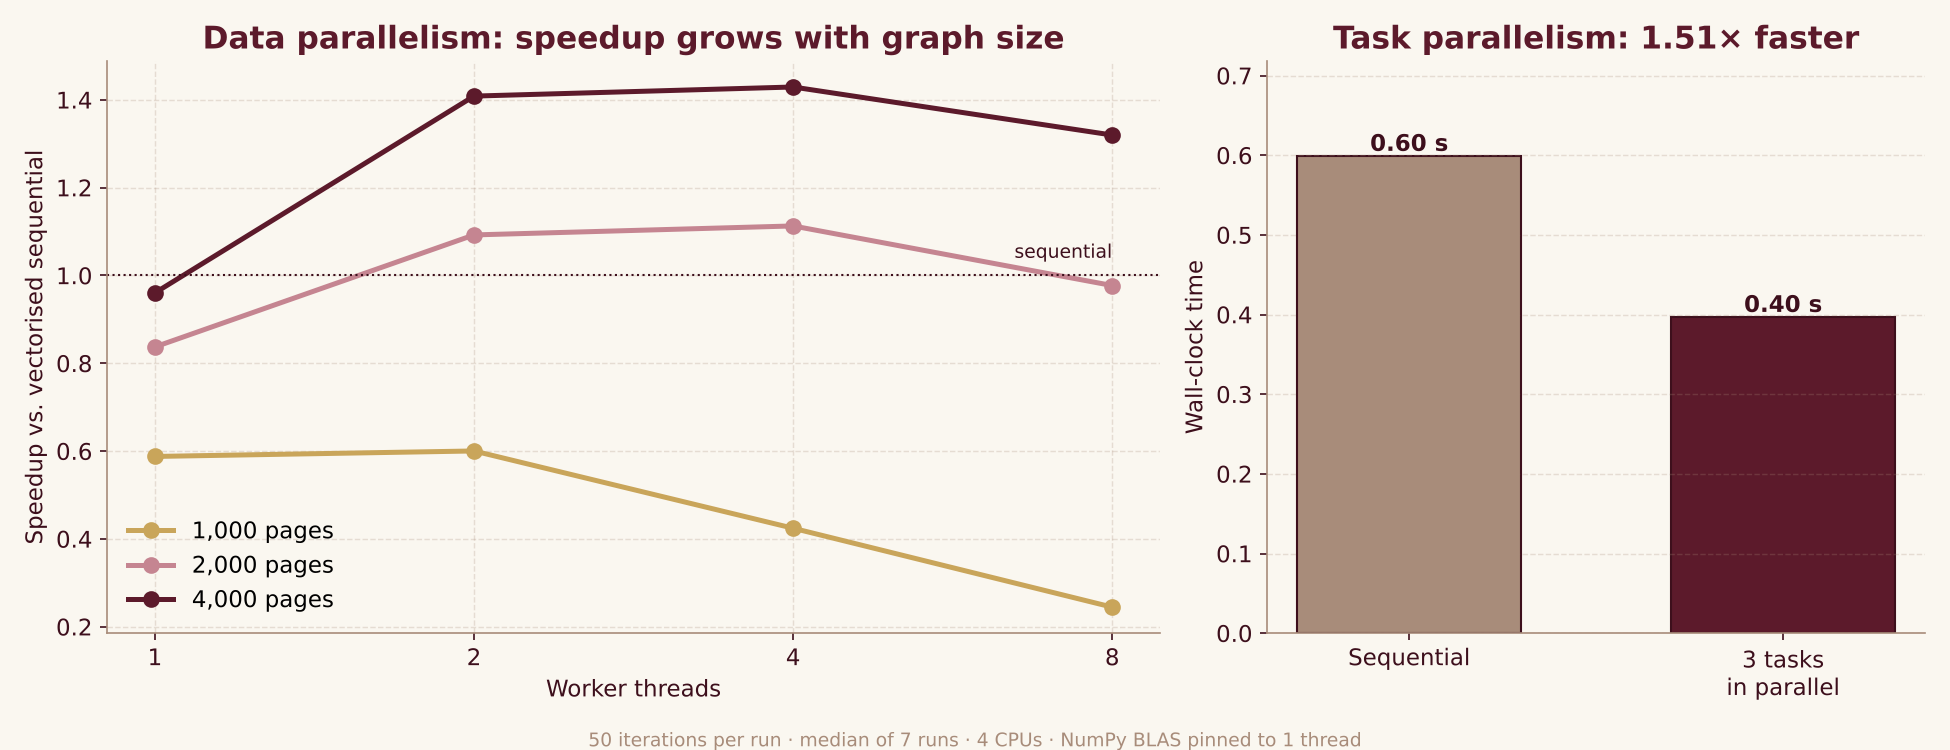

In [6]:
res = json.loads(Path("../results/benchmarks.json").read_text())
v = res["vectorisation"]
print(f"Vectorisation alone (n={v['n']}): {v['naive_s'] / v['vectorised_s']:.1f}x faster than a Python loop\n")
print(f"{'pages':>6} | " + " | ".join(f"{w} workers" for w in res["data_parallel"][0]["workers"]))
for row in res["data_parallel"]:
    print(f"{row['n']:>6} | " + " | ".join(f"{row['sequential_s'] / t:8.2f}x" for t in row["workers"].values()))
s = res["small_graph"]
print(f"\n15-page site: 4 workers are {s['parallel_4_s'] / s['sequential_s']:.0f}x SLOWER than sequential")
t = res["task_parallel"]
print(f"Task parallelism (n={t['n']}): {t['sequential_s'] / t['parallel_s']:.2f}x")
display(Image("../images/speedup.png", width=900))

## 7. What the numbers say

- **Parallelism only pays off when there is enough work.** On the 15-page site, the cost of coordinating threads is far larger than the computation itself. Speedup appears only from around 2,000 pages, and it grows with graph size.
- **The speedup levels off at about 1.4×.** A dense matrix-vector product is limited by **memory bandwidth**: the CPU cores spend their time waiting for the matrix to stream in from RAM, so extra threads add little. Going from 4 to 8 threads (more threads than CPUs) only adds overhead.
- **A fair baseline matters.** Without vectorising the sequential code too, the loop-versus-NumPy difference would look like a parallel speedup.
- **Task parallelism gives about 1.5×** with three tasks. It is limited by the longest task (Amdahl's law).